In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 15
df = pd.read_csv("retail_sales_dataset.csv")
print("RETAIL SALES DATASET LOADED SUCCESSFULLY")
print("=" * 45)
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())


RETAIL SALES DATASET LOADED SUCCESSFULLY
Dataset shape: (1000, 9)

First 5 rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn Names and Data Types:")
display(df.dtypes.to_frame(name="Data Type"))
print("\nMissing Values in Each Column:")
display(df.isnull().sum().to_frame(name="Missing Values"))
print("\nNumber of Duplicate Rows:", df.duplicated().sum())
print("\nNumerical Columns Summary:")
display(df.describe())
print("\nCategorical Columns Summary:")
display(df.describe(include="object"))


Number of rows: 1000
Number of columns: 9

Column Names and Data Types:


,Data Type
Transaction ID,int64
Date,object
Customer ID,object
Gender,object
Age,int64
Product Category,object
Quantity,int64
Price per Unit,int64
Total Amount,int64



Missing Values in Each Column:


,Missing Values
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0



Number of Duplicate Rows: 0

Numerical Columns Summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



Categorical Columns Summary:


,Date,Customer ID,Gender,Product Category
count,1000,1000,1000,1000
unique,345,1000,2,3
top,2023-05-16,CUST1000,Female,Clothing
freq,11,1,510,351


## Descriptive Statistical Analysis

Descriptive statistics help us understand the central tendency and variability of retail sales data.

- **Mean:** Average value.
- **Median:** Middle value.
- **Mode:** Most frequently occurring value.
- **Standard deviation:** Measures how widely values vary around the mean.

These statistics help identify typical transaction amounts, customer ages, quantities sold, and variations in sales.

In [3]:
numerical_df = df.select_dtypes(include=np.number)
statistics_df = pd.DataFrame({
    "Mean": numerical_df.mean(),
    "Median": numerical_df.median(),
    "Mode": numerical_df.mode().iloc[0],
    "Standard Deviation": numerical_df.std()
})

print("DESCRIPTIVE STATISTICS FOR NUMERICAL COLUMNS")
display(statistics_df.round(2))


DESCRIPTIVE STATISTICS FOR NUMERICAL COLUMNS


,Mean,Median,Mode,Standard Deviation
Transaction ID,500.50,500.5,1.0,288.82
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


## Time Series Analysis: Monthly and Quarterly Sales

Time series analysis helps identify sales trends, seasonal patterns, and periods of higher or lower business activity.



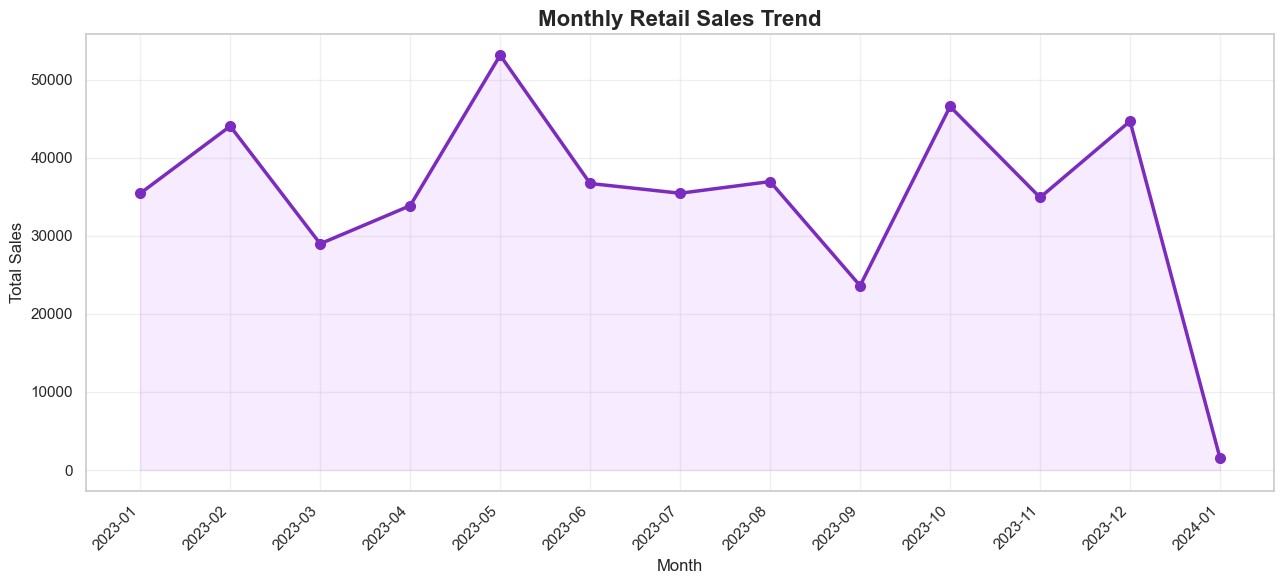

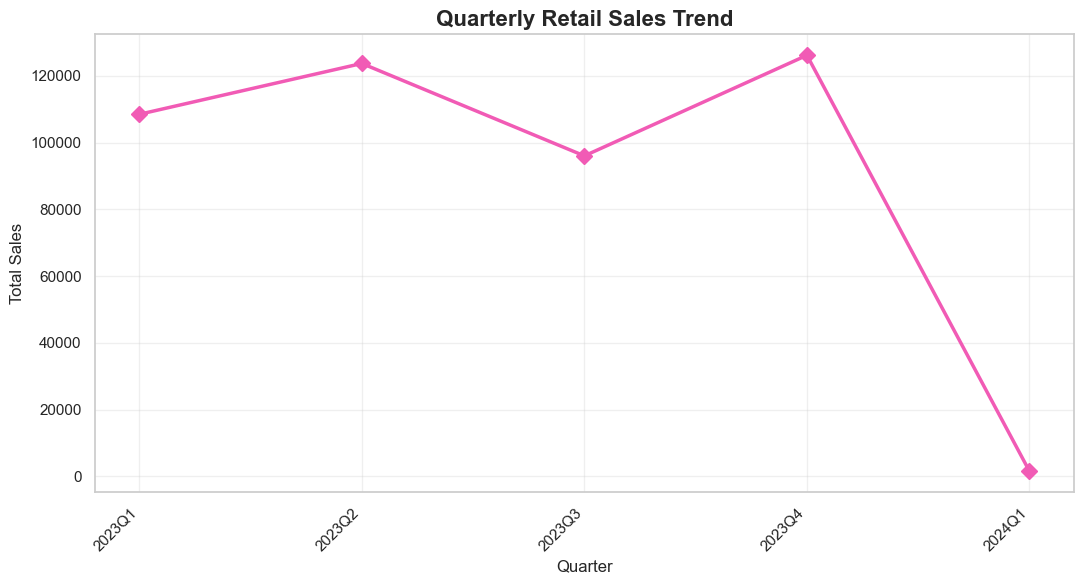

Monthly sales summary:


,Total Sales
Month,
2023-01,35450
2023-02,44060
2023-03,28990
2023-04,33870
2023-05,53150
2023-06,36715
2023-07,35465
2023-08,36960
2023-09,23620


Quarterly sales summary:


,Total Sales
Quarter,
2023Q1,108500
2023Q2,123735
2023Q3,96045
2023Q4,126190
2024Q1,1530


In [4]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

date_df = df.dropna(subset=["Date"]).copy()

date_df["Month"] = date_df["Date"].dt.to_period("M")
date_df["Quarter"] = date_df["Date"].dt.to_period("Q")

monthly_sales = date_df.groupby("Month")["Total Amount"].sum()
quarterly_sales = date_df.groupby("Quarter")["Total Amount"].sum()

plt.figure(figsize=(13, 6))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="#7B2CBF"
)
plt.fill_between(
    range(len(monthly_sales)),
    monthly_sales.values,
    alpha=0.15,
    color="#C77DFF"
)
plt.title("Monthly Retail Sales Trend", fontsize=16, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 6))
plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker="D",
    linewidth=2.5,
    markersize=8,
    color="#F15BB5"
)
plt.title("Quarterly Retail Sales Trend", fontsize=16, fontweight="bold")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Monthly sales summary:")
display(monthly_sales.rename("Total Sales").round(2).to_frame())

print("Quarterly sales summary:")
display(quarterly_sales.rename("Total Sales").round(2).to_frame())

### Observations

- The month with the highest sales was **May**.
- The month with the lowest sales was **January2024**.
- The highest-performing quarter was **2023Q4**.
- These patterns can help the business plan stock availability and promotional campaigns during high- and low-sales periods.

## Customer Demographics Analysis

This section explores the demographic characteristics of customers using their age and gender. Customers are grouped into age categories to identify the most common age groups, while gender distribution is analyzed to understand the customer composition.

The analysis uses bar charts to visualize customer distribution and identify patterns that can help the business improve customer targeting, personalize marketing campaigns, and develop effective sales strategies.

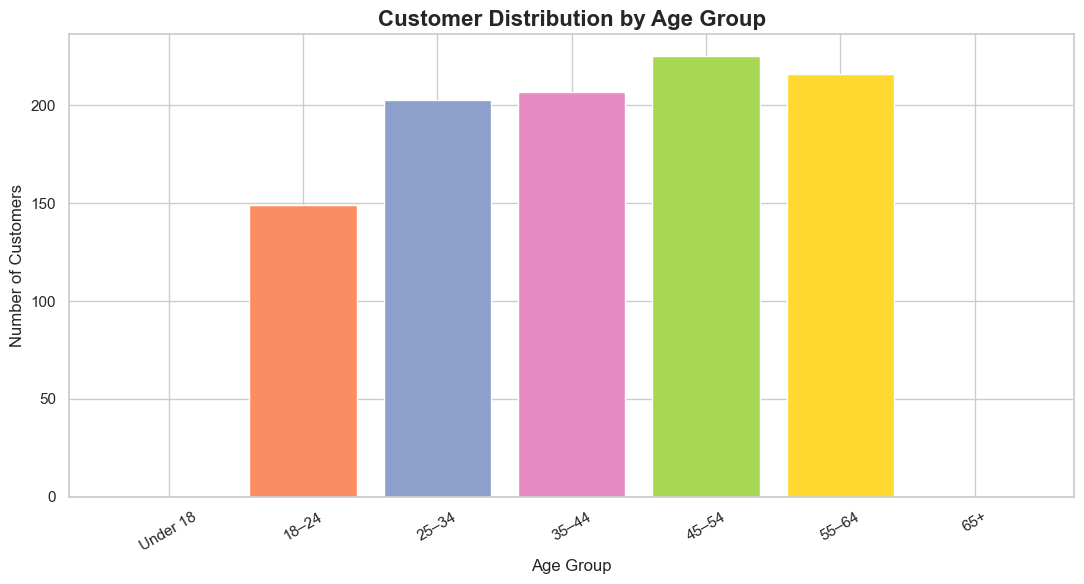

Most common age group: 45–54


,Customer Count
Age Group,
Under 18,0
18–24,149
25–34,203
35–44,207
45–54,225
55–64,216
65+,0


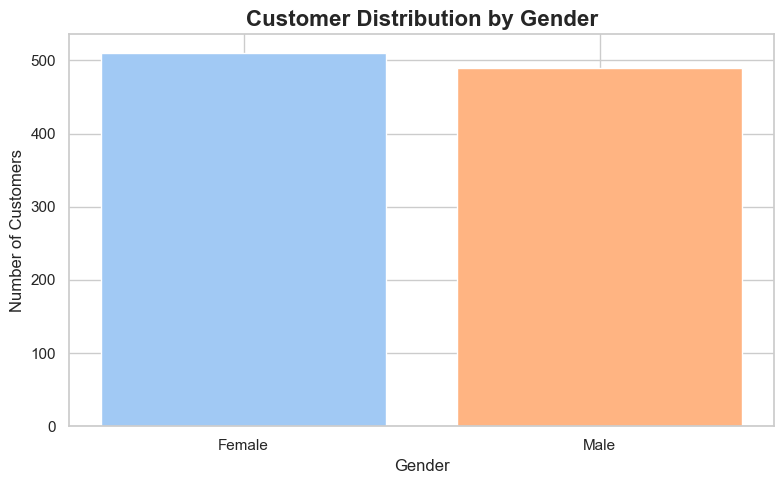

Most common gender: Female


,Customer Count
Gender,
Female,510
Male,490


In [5]:
age_bins = [0, 18, 25, 35, 45, 55, 65, 100]
age_labels = ["Under 18", "18–24", "25–34", "35–44", "45–54", "55–64", "65+"]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True,
    right=False
)

age_counts = df["Age Group"].value_counts().reindex(age_labels, fill_value=0)
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(11, 6))
plt.bar(
    age_counts.index.astype(str),
    age_counts.values,
    color=sns.color_palette("Set2", len(age_counts))
)
plt.title("Customer Distribution by Age Group", fontsize=16, fontweight="bold")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Most common age group:", age_counts.idxmax())
display(age_counts.rename("Customer Count").to_frame())

plt.figure(figsize=(8, 5))
plt.bar(
    gender_counts.index.astype(str),
    gender_counts.values,
    color=sns.color_palette("pastel", len(gender_counts))
)
plt.title("Customer Distribution by Gender", fontsize=16, fontweight="bold")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("Most common gender:", gender_counts.idxmax())
display(gender_counts.rename("Customer Count").to_frame())

### Observations
- The largest customer age group is 45-54.
- The gender distribution shows the number of transactions associated with each gender.
- The business can use these patterns to tailor marketing campaigns to its customer segments.


## Product Analysis

This section analyzes product performance by identifying the top 10 best-selling products and comparing revenue across product categories. The analysis uses sales quantity to understand which products or categories are most popular and total sales revenue to identify the categories that contribute most to business income.

The results can help the business optimize inventory, identify popular product categories, and make better pricing and marketing decisions.


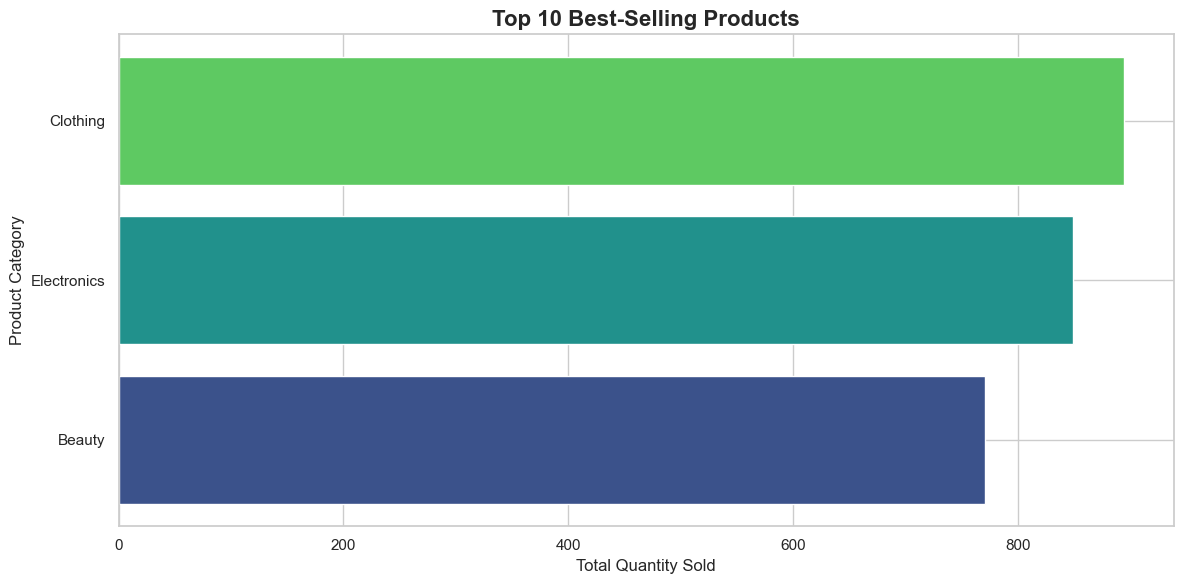

Top 10 best-selling products or categories:


,Quantity Sold
Product Category,
Clothing,894
Electronics,849
Beauty,771


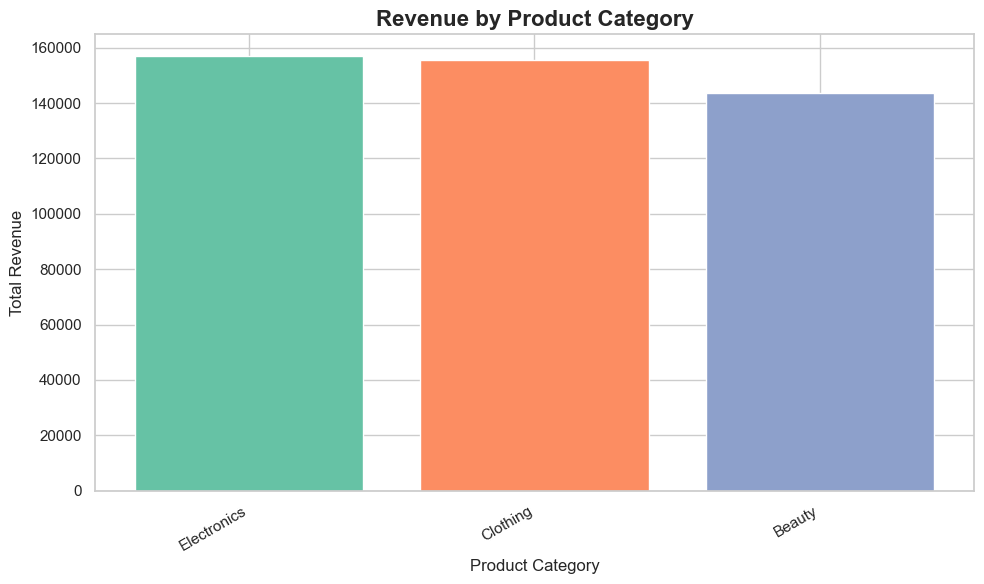

Revenue by product category:


,Total Revenue
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


Highest-selling item or category: Clothing
Highest-revenue category: Electronics


In [6]:

product_col = "Product" if "Product" in df.columns else "Product Category"

top_products = (
    df.groupby(product_col)["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
plt.barh(
    top_products.index.astype(str)[::-1],
    top_products.values[::-1],
    color=sns.color_palette("viridis", len(top_products))
)
plt.title("Top 10 Best-Selling Products", fontsize=16, fontweight="bold")
plt.xlabel("Total Quantity Sold")
plt.ylabel(product_col)
plt.tight_layout()
plt.show()

print("Top 10 best-selling products or categories:")
display(top_products.rename("Quantity Sold").to_frame())

category_revenue = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.bar(
    category_revenue.index.astype(str),
    category_revenue.values,
    color=sns.color_palette("Set2", len(category_revenue))
)
plt.title("Revenue by Product Category", fontsize=16, fontweight="bold")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("Revenue by product category:")
display(category_revenue.rename("Total Revenue").round(2).to_frame())

print("Highest-selling item or category:", top_products.idxmax())
print("Highest-revenue category:", category_revenue.idxmax())



## Correlation Analysis

Correlation analysis helps identify relationships between numerical variables in the retail sales dataset. A correlation matrix is visualized using a heatmap to show the strength and direction of relationships between variables such as age, quantity, price per unit, and total amount.

Positive correlations indicate that variables tend to increase together, while negative correlations indicate that one tends to decrease as the other increases. These relationships can help reveal useful patterns in customer purchasing behavior and sales performance.


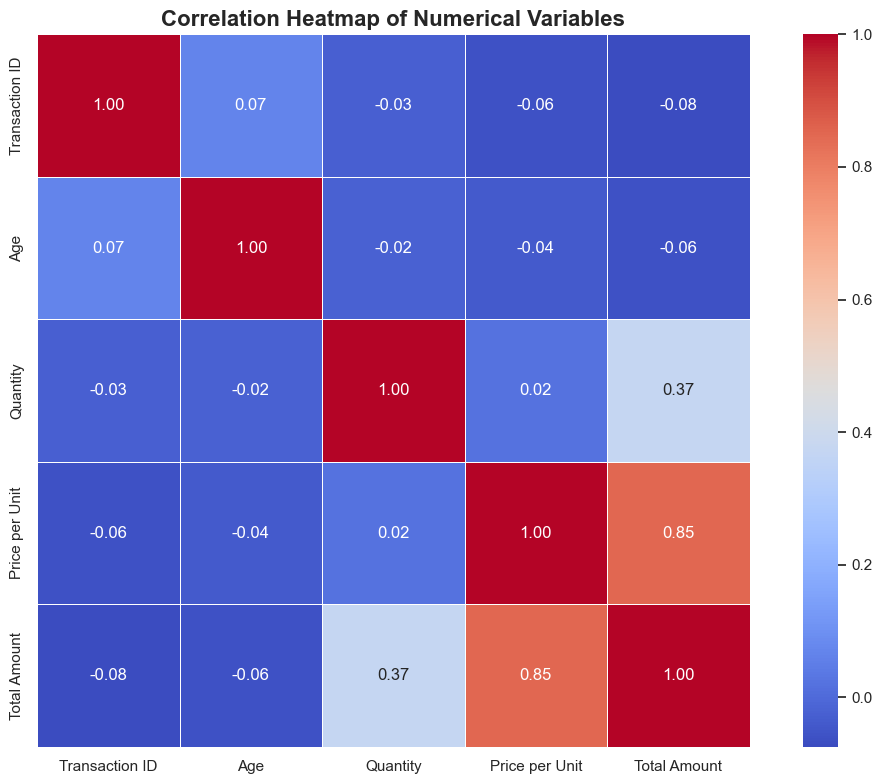

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
Transaction ID,1.00,0.07,-0.03,-0.06,-0.08
Age,0.07,1.00,-0.02,-0.04,-0.06
Quantity,-0.03,-0.02,1.00,0.02,0.37
Price per Unit,-0.06,-0.04,0.02,1.00,0.85
Total Amount,-0.08,-0.06,0.37,0.85,1.00


In [7]:

numerical_df = df.select_dtypes(include=np.number)
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True
)
plt.title("Correlation Heatmap of Numerical Variables", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

display(correlation_matrix.round(2))



## Additional Analysis: Average Spending by Age Group and Gender

This analysis explores how average transaction spending differs across customer age groups and gender. A grouped bar chart is used to compare average spending patterns and identify customer segments with higher average transaction values.

These insights can help the business design targeted promotions, personalize offers, and improve customer engagement strategies.


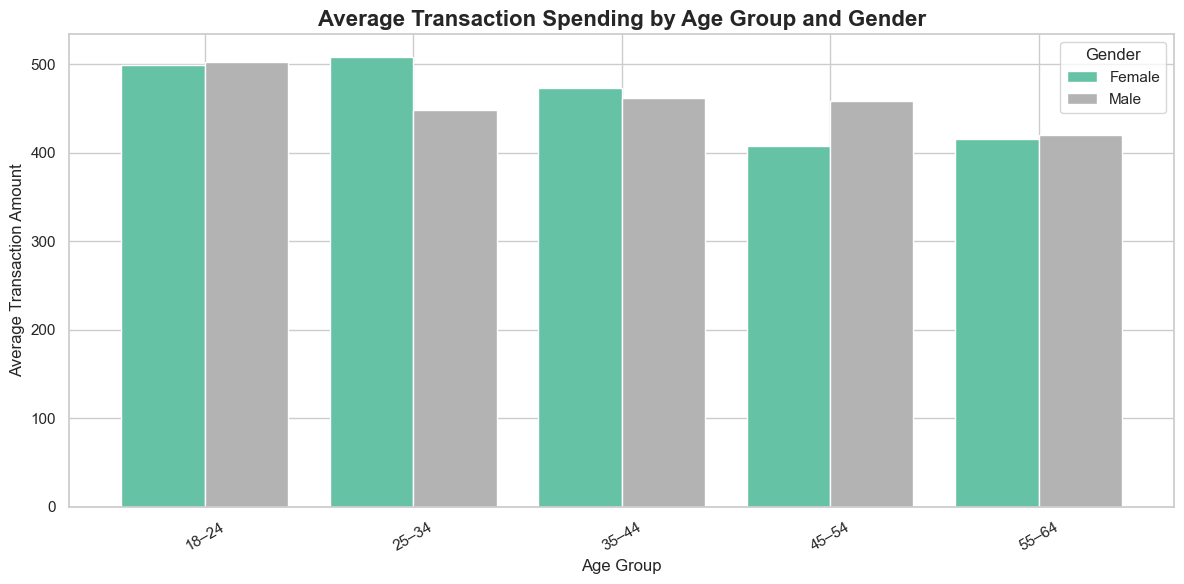

Gender,Female,Male
Age Group,,
18–24,498.89,502.99
25–34,508.33,447.92
35–44,472.90,461.79
45–54,407.17,458.27
55–64,415.41,419.72


Average transaction spending by gender:


,Average Spending
Gender,
Female,456.55
Male,455.43


Average transaction spending by age group:


,Average Spending
Age Group,
Under 18,NaN
18–24,501.01
25–34,478.28
35–44,467.80
45–54,432.16
55–64,417.55
65+,NaN


In [8]:

average_spending = df.pivot_table(
    index="Age Group",
    columns="Gender",
    values="Total Amount",
    aggfunc="mean",
    observed=False
)

average_spending.plot(
    kind="bar",
    figsize=(12, 6),
    colormap="Set2",
    width=0.8
)

plt.title("Average Transaction Spending by Age Group and Gender", fontsize=16, fontweight="bold")
plt.xlabel("Age Group")
plt.ylabel("Average Transaction Amount")
plt.xticks(rotation=30)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

display(average_spending.round(2))

print("Average transaction spending by gender:")
display(df.groupby("Gender")["Total Amount"].mean().round(2).to_frame(name="Average Spending"))

print("Average transaction spending by age group:")
display(df.groupby("Age Group", observed=False)["Total Amount"].mean().round(2).to_frame(name="Average Spending"))



## Conclusion and Business Recommendations

### Conclusion

The exploratory data analysis of the retail sales dataset provided insights into sales trends, customer demographics, product category performance, and relationships between numerical variables. Monthly and quarterly sales trends helped examine changes in revenue over time, while demographic analysis revealed the distribution of customers by age group and gender.

Product analysis highlighted the best-selling products or categories and the categories contributing the most revenue. The correlation heatmap and average spending analysis provided additional insights into purchasing patterns.

Overall, this analysis demonstrates how exploratory data analysis can support data-driven decision-making and help improve retail business performance.

### Actionable Business Recommendations

1. **Improve inventory management:** Stock more of the best-selling products or categories and monitor inventory regularly to reduce stock shortages and excess inventory.

2. **Optimize marketing campaigns:** Use age group and gender distributions to create targeted promotions for relevant customer segments.

3. **Increase revenue during low-sales periods:** Use monthly and quarterly sales trends to plan discounts, seasonal campaigns, and special offers during weaker sales periods.

4. **Focus on high-revenue categories:** Identify the categories generating the most revenue and consider improving their product availability, promotion, and customer experience.

5. **Improve customer engagement:** Compare average transaction spending across customer segments and develop loyalty programs or personalized offers where appropriate.

### Final Summary

This project demonstrates the use of Python, Pandas, Matplotlib, and Seaborn for retail sales data exploration and visualization. The findings can help retailers understand customer behavior, evaluate sales performance, improve inventory planning, and develop more effective business strategies.
